Total rows: 2000
Columns: ['designation', 'source_id', 'ra', 'dec', 'parallax', 'pmra', 'pmdec', 'ruwe', 'phot_g_mean_mag', 'bp_rp', 'radial_velocity', 'phot_variable_flag', 'non_single_star', 'has_xp_continuous', 'has_xp_sampled', 'has_rvs', 'has_epoch_photometry', 'has_epoch_rv', 'has_mcmc_gspphot', 'has_mcmc_msc', 'teff_gspphot', 'logg_gspphot', 'mh_gspphot', 'distance_gspphot', 'azero_gspphot', 'ag_gspphot', 'ebpminrp_gspphot', 'target_id', 'target_ra', 'target_dec', 'target_parallax', 'target_pm_ra', 'target_pm_dec', 'target_radial_velocity', 'epoch', 'target_separation (deg)']
Clean rows: 1733


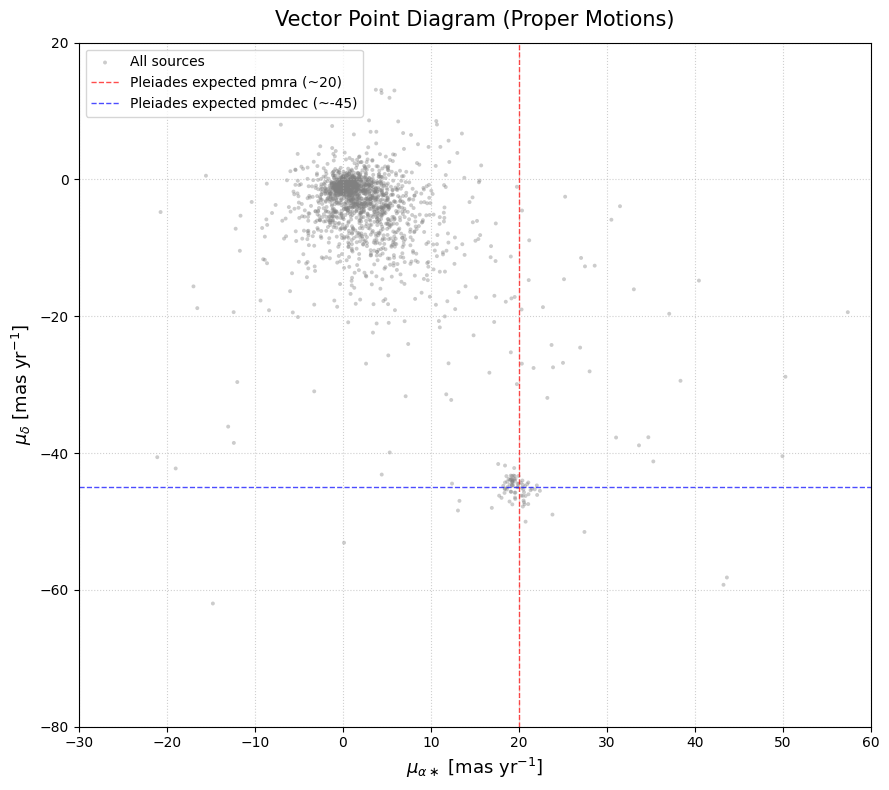

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


file_name = 'd6a7bb7a-cb1b-11f1-9670-bc97e148b76b-O-result.csv'  
df = pd.read_csv(file_name)

print(f"Total rows: {len(df)}")
print(f"Columns: {list(df.columns)}")

clean_cols = ['ra', 'dec', 'parallax', 'pmra', 'pmdec', 'phot_g_mean_mag', 'bp_rp']

valid_cols = [col for col in clean_cols if col in df.columns]
df_clean = df.dropna(subset=valid_cols).copy()

print(f"Clean rows: {len(df_clean)}")

plt.figure(figsize=(9, 8))


plt.scatter(
    df_clean['pmra'], 
    df_clean['pmdec'], 
    s=8, 
    c='gray', 
    alpha=0.4, 
    edgecolors='none',
    label='All sources'
)


plt.axvline(x=20.0, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Pleiades expected pmra (~20)')
plt.axhline(y=-45.0, color='blue', linestyle='--', linewidth=1, alpha=0.7, label='Pleiades expected pmdec (~-45)')


plt.xlabel(r'$\mu_{\alpha \ast}$ [mas yr$^{-1}$]', fontsize=13)
plt.ylabel(r'$\mu_{\delta}$ [mas yr$^{-1}$]', fontsize=13)
plt.title('Vector Point Diagram (Proper Motions)', fontsize=15, pad=12)


plt.xlim(-30, 60)
plt.ylim(-80, 20)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='upper left')
plt.tight_layout()

plt.show()


Total cluster members identified: 71
Mean Parallax: 7.38 mas
Estimated Distance: 135.6 pc


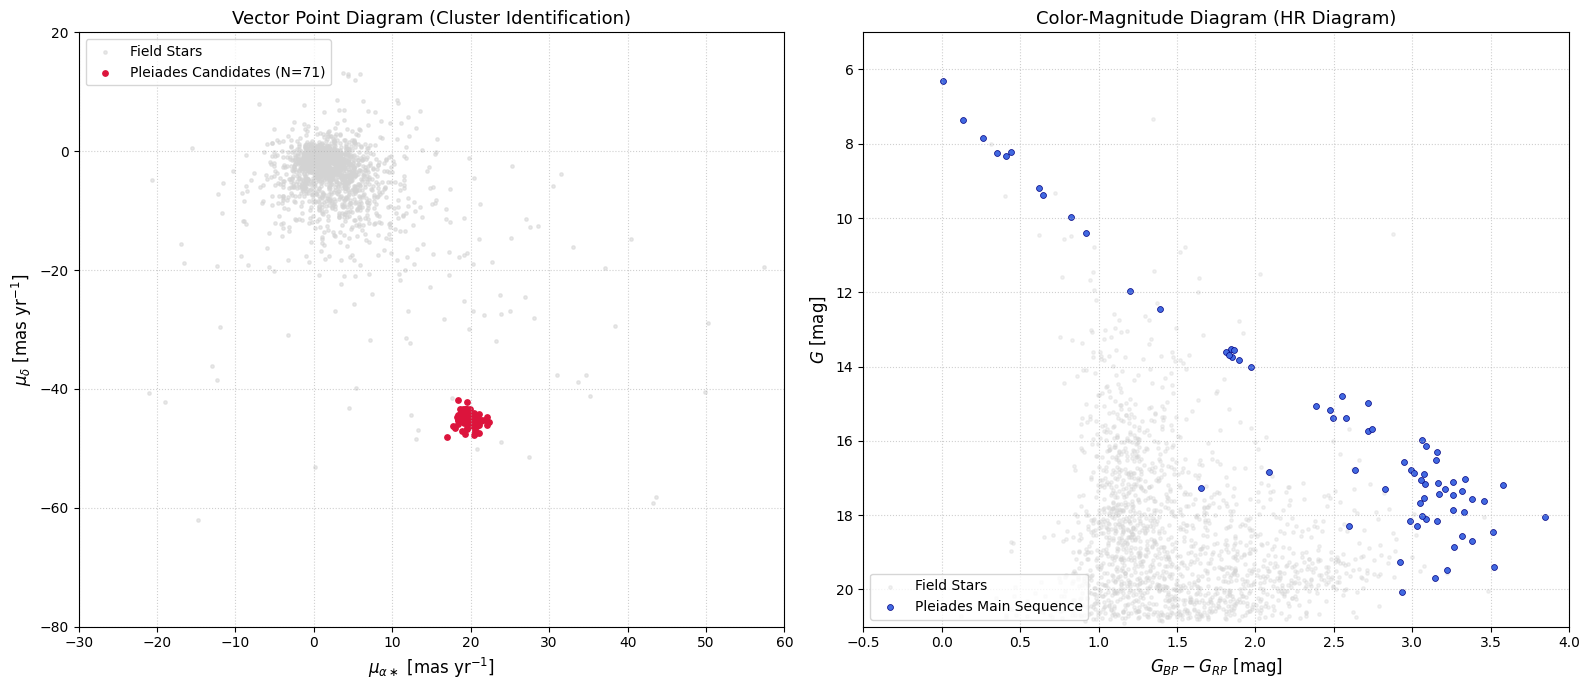

In [2]:

pmra_center, pmdec_center = 19.8, -45.4
radius = 4.0  


dist_pm = np.sqrt((df_clean['pmra'] - pmra_center)**2 + (df_clean['pmdec'] - pmdec_center)**2)
is_pm_member = dist_pm < radius


is_plx_member = (df_clean['parallax'] > 6.0) & (df_clean['parallax'] < 8.5)


members = df_clean[is_pm_member & is_plx_member].copy()
field_stars = df_clean[~(is_pm_member & is_plx_member)].copy()

print(f"Total cluster members identified: {len(members)}")
print(f"Mean Parallax: {members['parallax'].mean():.2f} mas")
print(f"Estimated Distance: {1000 / members['parallax'].mean():.1f} pc")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))


ax1.scatter(field_stars['pmra'], field_stars['pmdec'], s=6, c='lightgray', label='Field Stars', alpha=0.5)
ax1.scatter(members['pmra'], members['pmdec'], s=15, c='crimson', label=f'Pleiades Candidates (N={len(members)})')
ax1.set_xlabel(r'$\mu_{\alpha \ast}$ [mas yr$^{-1}$]', fontsize=12)
ax1.set_ylabel(r'$\mu_{\delta}$ [mas yr$^{-1}$]', fontsize=12)
ax1.set_title('Vector Point Diagram (Cluster Identification)', fontsize=13)
ax1.set_xlim(-30, 60)
ax1.set_ylim(-80, 20)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left')


ax2.scatter(field_stars['bp_rp'], field_stars['phot_g_mean_mag'], s=6, c='lightgray', alpha=0.3, label='Field Stars')
ax2.scatter(members['bp_rp'], members['phot_g_mean_mag'], s=18, c='royalblue', edgecolors='navy', linewidth=0.5, label='Pleiades Main Sequence')


ax2.invert_yaxis()
ax2.set_xlabel(r'$G_{BP} - G_{RP}$ [mag]', fontsize=12)
ax2.set_ylabel(r'$G$ [mag]', fontsize=12)
ax2.set_title('Color-Magnitude Diagram (HR Diagram)', fontsize=13)
ax2.set_xlim(-0.5, 4.0)
ax2.set_ylim(21, 5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()
